# SPX SABR price calibration: inspect every step

This notebook follows **one market snapshot** from the raw ETH/RTH CSVs through quote checks, a parity forward, OTM option selection, a near-ATM straddle, SABR calibration, and the risk-neutral density handoff.

**Change `TARGET_TIME` below and rerun all cells** to inspect another snapshot. Times in the source files are New York clock times. The option filename suffix is the last trading date; these two SPX monthly contracts settle at 09:30 ET on the next trading day. The fit uses market **prices**, with fixed $\beta=0.7$.

`raw files → valid bid/ask quotes → forward and expiry → OTM prices + one straddle → SABR model prices → residuals → density`

## 0. Choose a snapshot

In [1]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")

from smile_per_event import find_session
from key_strike_iv import find_expiry, settlement_time
from quote_selection import (
    DATA_DIR, load_quote_rows, build_quote_table, load_market_snapshot,
)
from sabr_calibration import calibrate_snapshot, calibrate_times
from breeden_litzenberger import run_snapshot

PROJECT_ROOT = Path.cwd()
assert (PROJECT_ROOT / "quote_selection.py").exists(), "Run this notebook from the Stochastic Proj folder"
TARGET_TIME = pd.Timestamp("2025-04-02 09:31:24")
# Another useful example: pd.Timestamp("2025-04-07 09:00:00")  # ETH; SPX spot is corrected from ES
print(f"Project: {PROJECT_ROOT}")
print(f"Requested snapshot: {TARGET_TIME} New York time")

Project: /Users/calvinliu/Desktop/Stochastic Proj
Requested snapshot: 2025-04-02 09:31:24 New York time


## 1. Locate the session, contract, and source files

Each snapshot needs four option grids and an asset grid. The filename suffix below is the **last trading date**, not the AM settlement timestamp.

In [2]:
data_folder = str(DATA_DIR) + "/"
found = find_session(TARGET_TIME, data_folder)
if found is None:
    raise ValueError(f"No ETH/RTH session contains {TARGET_TIME}")
session, file_date = found
last_trading_date = find_expiry(session, file_date, data_folder)
settlement = settlement_time(last_trading_date)
source_files = [
    DATA_DIR / session / f"{file_date}_{side}_{quote_side}_{last_trading_date}.csv"
    for side in ("call", "put") for quote_side in ("bid", "ask")
] + [DATA_DIR / session / f"{file_date}_assets.csv"]
display(pd.DataFrame({
    "source": [p.name for p in source_files],
    "exists": [p.exists() for p in source_files],
}))
print(f"Session: {session}; file date: {file_date}; last trading date: {last_trading_date}")
print(f"AM settlement: {settlement} New York time")

Session: RTH; file date: 2025-04-02; last trading date: 20250416
AM settlement: 2025-04-17 09:30:00 New York time


,source,exists
0,2025-04-02_call_bid_20250416.csv,True
1,2025-04-02_call_ask_20250416.csv,True
2,2025-04-02_put_bid_20250416.csv,True
3,2025-04-02_put_ask_20250416.csv,True
4,2025-04-02_assets.csv,True


## 2. Select the actual source rows

For each CSV, take the last row at or before the requested time. A row more than 60 seconds old is rejected. The table shows the **actual** observation times, which can differ slightly between files.

In [3]:
rows, row_times, assets_grid = load_quote_rows(
    session, file_date, last_trading_date, TARGET_TIME, DATA_DIR, max_age_seconds=60
)
row_audit = pd.DataFrame([
    {"source": name, "row_time": time, "age_seconds": (TARGET_TIME - time).total_seconds()}
    for name, time in row_times.items()
])
display(row_audit)
print("Asset row:")
display(rows["assets"].to_frame("value").T)
sample_strike = min((float(k) for k in rows["call_ask"].index), key=lambda k: abs(k - 5600))
print(f"Raw option bid/ask at strike {sample_strike:g}:")
display(pd.DataFrame([
    {"side": side, "bid": rows[f"{side}_bid"][str(sample_strike)],
     "ask": rows[f"{side}_ask"][str(sample_strike)]}
    for side in ("call", "put")
]))

Asset row:
Raw option bid/ask at strike 5600:


,source,row_time,age_seconds
0,call_bid,2025-04-02 09:31:21.159704,2.840296
1,call_ask,2025-04-02 09:31:21.159704,2.840296
2,put_bid,2025-04-02 09:31:21.159704,2.840296
3,put_ask,2025-04-02 09:31:21.159704,2.840296
4,assets,2025-04-02 09:31:21.159704,2.840296


,SPX,ES_BID,ES_ASK,VIX
value,5573.42,5614.25,5614.5,23.51


,side,bid,ask
0,call,89.3,90.3
1,put,106.6,107.6


## 3. Validate bid/ask quotes and compute mids

The selector rejects nonfinite, nonpositive, crossed, and near-minimum-tick quotes. It retains bid and ask so the fit can be checked against the market spread.

In [4]:
valid_quotes, strike_grid, call_mids, put_mids, exclusions = build_quote_table(rows)
print(f"Raw possibilities: {2 * len(strike_grid)}; valid call/put quotes: {len(valid_quotes)}")
print("Excluded quote counts:", exclusions)
print("Valid quotes closest to the center of the strike grid:")
center = float(np.median(strike_grid))
display(valid_quotes.assign(distance=lambda d: abs(d["strike"] - center))
        .sort_values(["distance", "side"]).drop(columns="distance").head(12))

Raw possibilities: 162; valid call/put quotes: 156
Excluded quote counts: {'nonpositive_quote': 6}
Valid quotes closest to the center of the strike grid:


,side,strike,bid,ask,mid
40,call,5600.0,89.3,90.3,89.80
115,put,5600.0,106.6,107.6,107.10
39,call,5575.0,103.6,104.8,104.20
41,call,5625.0,76.0,77.1,76.55
114,put,5575.0,96.0,97.0,96.50
116,put,5625.0,118.2,119.3,118.75
38,call,5550.0,118.7,119.9,119.30
42,call,5650.0,63.8,64.7,64.25
113,put,5550.0,86.2,87.2,86.70
117,put,5650.0,130.8,132.1,131.45


## 4. Establish the pricing inputs

The parity forward uses a strike with valid call and put mids. Maturity is ACT/365 calendar time to the AM settlement timestamp. The shared risk-free rate is read from the project's cached Treasury data. Spot is displayed as a diagnostic; pricing uses the forward.

In [5]:
snapshot = load_market_snapshot(TARGET_TIME)
inputs = pd.DataFrame([
    ("session", snapshot.session),
    ("last trading date", snapshot.last_trading_date),
    ("AM settlement", snapshot.settlement_time),
    ("time to settlement (years)", snapshot.maturity),
    ("risk-free rate", snapshot.rate),
    ("discount factor", snapshot.discount),
    ("parity forward", snapshot.forward),
    ("spot diagnostic", snapshot.spot),
    ("spot reconstructed from ES", snapshot.spot_from_es),
], columns=["input", "value"])
display(inputs)
assert snapshot.maturity > 0 and snapshot.forward > 0

,input,value
0,session,RTH
1,last trading date,20250416
2,AM settlement,2025-04-17 09:30:00
3,time to settlement (years),0.041093
4,risk-free rate,0.04365
5,discount factor,0.998208
6,parity forward,5582.713824
7,spot diagnostic,5573.42
8,spot reconstructed from ES,False


## 5. Construct calibration targets

Below the forward we fit put mids; above it we fit call mids. At the **nearest strike with both valid sides**, the call-plus-put mid becomes one straddle target. The individual call or put at that strike is removed, preventing double counting.

In [6]:
print("Calibration target counts:")
display(snapshot.targets.groupby("kind").size().rename("count").to_frame())
print("Exclusions and skipped OTM sides:", snapshot.exclusions)
straddle = snapshot.targets.loc[snapshot.targets["kind"] == "straddle"].iloc[0]
legs = snapshot.quotes.loc[snapshot.quotes["strike"] == snapshot.atm_strike].copy()
legs = pd.concat([legs, snapshot.targets.loc[snapshot.targets["kind"] == "straddle"].rename(columns={"kind": "side"})], ignore_index=True)
display(legs[["side", "strike", "bid", "ask", "mid"]])
assert snapshot.targets.loc[snapshot.targets["strike"] == snapshot.atm_strike, "kind"].tolist() == ["straddle"]
print(f"Near-ATM strike {snapshot.atm_strike:g}; forward {snapshot.forward:.2f}; straddle mid {straddle.mid:.2f}")
print("First and last selected targets:")
display(pd.concat([snapshot.targets.head(5), snapshot.targets.tail(5)]))

Calibration target counts:
Exclusions and skipped OTM sides: {'nonpositive_quote': 6, 'missing_otm_side': 6}
Near-ATM strike 5575; forward 5582.71; straddle mid 200.70
First and last selected targets:


,count
kind,
call,35
put,39
straddle,1


,side,strike,bid,ask,mid
0,call,5575.0,103.6,104.8,104.2
1,put,5575.0,96.0,97.0,96.5
2,straddle,5575.0,199.6,201.8,200.7


,kind,strike,bid,ask,mid
0,put,4600.0,3.00,3.20,3.100
1,put,4625.0,3.10,3.40,3.250
2,put,4650.0,3.30,3.50,3.400
3,put,4675.0,3.40,3.70,3.550
4,put,4700.0,3.60,3.80,3.700
70,call,6350.0,0.05,0.25,0.150
71,call,6375.0,0.05,0.25,0.150
72,call,6400.0,0.05,0.25,0.150
73,call,6425.0,0.05,0.25,0.150
74,call,6500.0,0.05,0.20,0.125


### 5a. Inspect every rejected and skipped quote

The first table shows **all rejected call/put bid–ask pairs** at this snapshot. The second shows only strikes where the selected OTM side was unavailable after filtering. These are strike-level skips, not missing files. The raw values are shown before any replacement or midpoint filtering.

In [7]:
from key_strike_iv import MIN_MID

raw_records = []
for side in ("call", "put"):
    bids = {float(k): float(v) for k, v in rows[f"{side}_bid"].items()}
    asks = {float(k): float(v) for k, v in rows[f"{side}_ask"].items()}
    for strike in strike_grid:
        bid, ask = bids[strike], asks[strike]
        raw_mid = (bid + ask) / 2
        if not (np.isfinite(bid) and np.isfinite(ask)):
            reason = "nonfinite_quote"
        elif bid <= 0 or ask <= 0:
            reason = "nonpositive_quote"
        elif ask < bid:
            reason = "crossed_quote"
        elif raw_mid < MIN_MID:
            reason = "below_min_mid"
        else:
            reason = None
        raw_records.append({"side": side, "strike": strike, "bid": bid,
                            "ask": ask, "raw_mid": raw_mid, "reason": reason})

raw_audit = pd.DataFrame(raw_records)
invalid_quotes = raw_audit[raw_audit["reason"].notna()].sort_values(["strike", "side"])
print(f"Rejected quote pairs: {len(invalid_quotes)}")
display(invalid_quotes)

valid_keys = set(zip(snapshot.quotes["side"], snapshot.quotes["strike"]))
skipped_records = []
for strike in sorted(raw_audit["strike"].unique()):
    if strike == snapshot.atm_strike:
        continue  # one call-plus-put straddle replaces the individual target here
    wanted_side = "put" if strike < snapshot.forward else "call"
    if (wanted_side, strike) in valid_keys:
        continue
    rejected = raw_audit[(raw_audit["side"] == wanted_side) & (raw_audit["strike"] == strike)].iloc[0]
    other_side = "call" if wanted_side == "put" else "put"
    other = raw_audit[(raw_audit["side"] == other_side) & (raw_audit["strike"] == strike)].iloc[0]
    skipped_records.append({"strike": strike, "wanted_otm_side": wanted_side,
                            "bid": rejected.bid, "ask": rejected.ask, "raw_mid": rejected.raw_mid,
                            "reason": rejected.reason, "opposite_side": other_side,
                            "opposite_bid": other.bid, "opposite_ask": other.ask})
skipped_otm = pd.DataFrame(skipped_records)
print(f"Skipped OTM strikes: {len(skipped_otm)}")
display(skipped_otm)
assert len(skipped_otm) == snapshot.exclusions["missing_otm_side"]

Rejected quote pairs: 6
Skipped OTM strikes: 6


,side,strike,bid,ask,raw_mid,reason
74,call,6450.0,-1.0,0.25,-0.375,nonpositive_quote
75,call,6475.0,-1.0,0.25,-0.375,nonpositive_quote
77,call,6525.0,-1.0,0.20,-0.400,nonpositive_quote
78,call,6550.0,-1.0,0.20,-0.400,nonpositive_quote
79,call,6575.0,-1.0,0.20,-0.400,nonpositive_quote
80,call,6600.0,-1.0,0.20,-0.400,nonpositive_quote


,strike,wanted_otm_side,bid,ask,raw_mid,reason,opposite_side,opposite_bid,opposite_ask
0,6450.0,call,-1.0,0.25,-0.375,nonpositive_quote,put,858.5,874.4
1,6475.0,call,-1.0,0.25,-0.375,nonpositive_quote,put,883.4,898.2
2,6525.0,call,-1.0,0.20,-0.400,nonpositive_quote,put,933.3,951.4
3,6550.0,call,-1.0,0.20,-0.400,nonpositive_quote,put,958.2,972.3
4,6575.0,call,-1.0,0.20,-0.400,nonpositive_quote,put,983.2,997.2
5,6600.0,call,-1.0,0.20,-0.400,nonpositive_quote,put,1008.1,1022.1


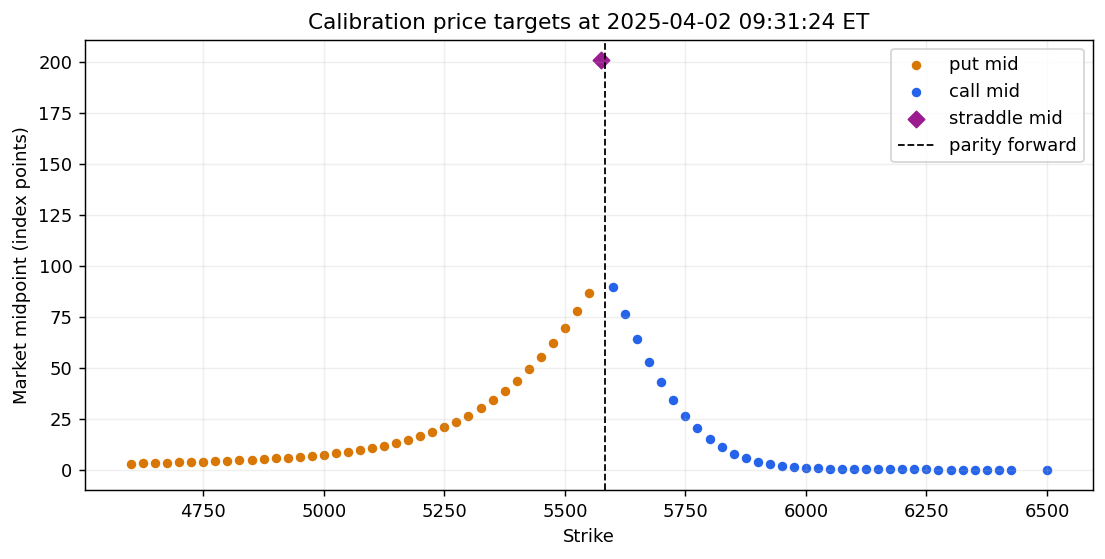

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for kind, color, marker in [("put", "#d97706", "o"), ("call", "#2563eb", "o"), ("straddle", "#9b1c8f", "D")]:
    part = snapshot.targets[snapshot.targets["kind"] == kind]
    ax.scatter(part["strike"], part["mid"], label=f"{kind} mid", color=color, marker=marker, s=40 if kind == "straddle" else 18)
ax.axvline(snapshot.forward, color="black", linestyle="--", linewidth=1, label="parity forward")
ax.set(xlabel="Strike", ylabel="Market midpoint (index points)", title=f"Calibration price targets at {TARGET_TIME:%Y-%m-%d %H:%M:%S} ET")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

## 6. Fit SABR parameters to prices

For each trial $(\alpha,\rho,\nu)$, the code computes Hagan's Black implied volatility at every selected strike, converts it to a discounted-forward call, put, or straddle price, and gives `least_squares` one **model price minus market mid** residual per target. $\beta=0.7$ is fixed.

In [9]:
fit = calibrate_snapshot(snapshot, beta=0.7)
straddle_fit = fit.fitted_targets.loc[fit.fitted_targets["kind"] == "straddle"].iloc[0]
straddle_outside_spread = max(straddle_fit.bid - straddle_fit.model_price,
                              straddle_fit.model_price - straddle_fit.ask, 0.0)
fit_summary = pd.DataFrame([
    ("alpha", fit.alpha), ("beta (fixed)", fit.beta),
    ("rho", fit.rho), ("nu", fit.nu),
    ("optimizer success", fit.success),
    ("price RMSE", fit.price_rmse),
    ("model prices inside bid-ask", f"{fit.within_bid_ask}/{len(fit.fitted_targets)}"),
    ("straddle market mid", straddle_fit.mid),
    ("straddle model price", straddle_fit.model_price),
    ("straddle price error", straddle_fit.price_error),
    ("straddle relative error (%)", 100 * straddle_fit.price_error / straddle_fit.mid),
    ("straddle distance outside bid-ask", straddle_outside_spread),
    ("optimizer message", fit.message),
], columns=["measure", "value"])
display(fit_summary)
assert fit.success

,measure,value
0,alpha,2.929337
1,beta (fixed),0.7
2,rho,-0.824886
3,nu,2.46152
4,optimizer success,True
5,price RMSE,0.914427
6,model prices inside bid-ask,8/75
7,straddle market mid,200.7
8,straddle model price,198.950692
9,straddle price error,-1.749308


### 6a. What if the straddle gets more priority?

This is a **diagnostic comparison**, not a change to the saved calibration. The baseline gives every price residual the same coefficient. The alternative doubles only the straddle residual during optimization, then reports **unweighted** errors for an apples-to-apples comparison.

In [10]:
from scipy.optimize import least_squares
from sabr_calibration import price_residuals, summarize_fit

straddle_mask = snapshot.targets["kind"].to_numpy() == "straddle"
objective_weights = np.where(straddle_mask, 2.0, 1.0)
weighted_optimizer = least_squares(
    lambda x: objective_weights * price_residuals(x, snapshot, beta=0.7),
    x0=[fit.alpha, fit.rho, fit.nu],
    bounds=([1e-8, -0.999, 1e-6], [100.0, 0.999, 10.0]),
)
weighted_targets, weighted_rmse, weighted_inside = summarize_fit(
    snapshot, weighted_optimizer.x, beta=0.7
)

def fit_comparison_row(label, table, rmse, inside):
    atm = table[table["kind"] == "straddle"].iloc[0]
    others = table[table["kind"] != "straddle"]
    return {
        "objective": label,
        "straddle_error": atm.price_error,
        "straddle_outside_bid_ask": max(atm.bid - atm.model_price,
                                         atm.model_price - atm.ask, 0.0),
        "other_quotes_RMSE": float(np.sqrt(np.mean(others["price_error"] ** 2))),
        "all_quotes_RMSE": rmse,
        "inside_bid_ask": f"{inside}/{len(table)}",
    }
comparison = pd.DataFrame([
    fit_comparison_row("equal residual coefficients", fit.fitted_targets,
                       fit.price_rmse, fit.within_bid_ask),
    fit_comparison_row("2× straddle coefficient", weighted_targets,
                       weighted_rmse, weighted_inside),
])
display(comparison)

,objective,straddle_error,straddle_outside_bid_ask,other_quotes_RMSE,all_quotes_RMSE,inside_bid_ask
0,equal residual coefficients,-1.749308,0.649308,0.897844,0.914427,8/75
1,2× straddle coefficient,-0.969347,0.000000,0.930272,0.930804,10/75


## 7. Inspect fitted prices and errors

The straddle remains one residual. The table and chart reveal where the fit misses, including whether each model price lies inside the observed bid–ask interval.

In [11]:
fitted = fit.fitted_targets
per_kind = fitted.groupby("kind").agg(
    targets=("strike", "count"),
    price_rmse=("price_error", lambda x: float(np.sqrt(np.mean(np.square(x))))),
    inside_bid_ask=("within_bid_ask", "sum"),
)
display(per_kind)
print("Largest absolute price errors:")
display(fitted.assign(abs_error=lambda d: abs(d["price_error"]))
        .sort_values("abs_error", ascending=False).head(12)
        [["kind", "strike", "bid", "mid", "ask", "model_vol", "model_price", "price_error", "within_bid_ask"]])

Largest absolute price errors:


,targets,price_rmse,inside_bid_ask
kind,,,
call,35,0.397674,5
put,39,1.177983,3
straddle,1,1.749308,0


,kind,strike,bid,mid,ask,model_vol,model_price,price_error,within_bid_ask
1,put,4625.0,3.1,3.25,3.4,0.399294,1.395519,-1.854481,False
2,put,4650.0,3.3,3.40,3.5,0.394575,1.553055,-1.846945,False
0,put,4600.0,3.0,3.10,3.2,0.404019,1.254385,-1.845615,False
3,put,4675.0,3.4,3.55,3.7,0.389862,1.728961,-1.821039,False
4,put,4700.0,3.6,3.70,3.8,0.385154,1.925447,-1.774553,False
5,put,4725.0,3.8,3.90,4.0,0.380450,2.144997,-1.755003,False
39,straddle,5575.0,199.6,200.70,201.8,0.220792,198.950692,-1.749308,False
6,put,4750.0,4.0,4.10,4.2,0.375751,2.390402,-1.709598,False
7,put,4775.0,4.2,4.30,4.4,0.371056,2.664799,-1.635201,False
8,put,4800.0,4.4,4.50,4.6,0.366364,2.971716,-1.528284,False


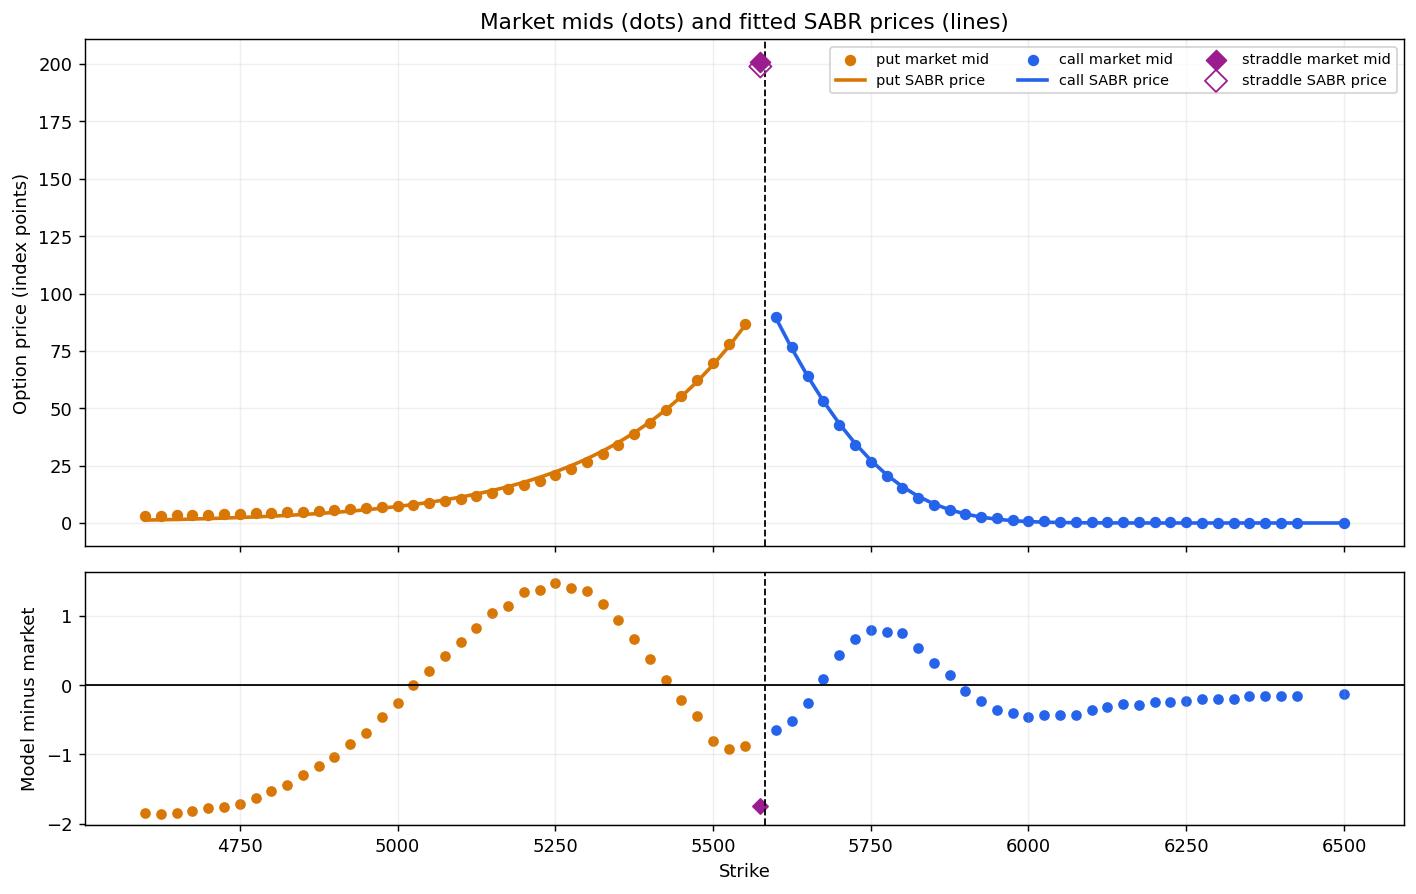

In [12]:
fig, (price_ax, error_ax) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for kind, color in [("put", "#d97706"), ("call", "#2563eb")]:
    part = fitted[fitted["kind"] == kind].sort_values("strike")
    price_ax.scatter(part["strike"], part["mid"], color=color, s=28,
                     label=f"{kind} market mid", zorder=3)
    price_ax.plot(part["strike"], part["model_price"], color=color, linewidth=2,
                  label=f"{kind} SABR price", zorder=2)
    error_ax.scatter(part["strike"], part["price_error"], color=color, s=24, label=kind)

atm = fitted[fitted["kind"] == "straddle"].iloc[0]
price_ax.scatter([atm.strike], [atm.mid], color="#9b1c8f", marker="D", s=60,
                 label="straddle market mid", zorder=5)
price_ax.scatter([atm.strike], [atm.model_price], facecolors="none",
                 edgecolors="#9b1c8f", marker="D", s=75,
                 label="straddle SABR price", zorder=5)
price_ax.plot([atm.strike, atm.strike], [atm.mid, atm.model_price],
              color="#9b1c8f", linewidth=1.5)
error_ax.scatter([atm.strike], [atm.price_error], color="#9b1c8f",
                 marker="D", s=35, label="straddle")

price_ax.axvline(snapshot.forward, color="black", linestyle="--", linewidth=1)
error_ax.axhline(0, color="black", linewidth=1)
error_ax.axvline(snapshot.forward, color="black", linestyle="--", linewidth=1)
price_ax.set(ylabel="Option price (index points)",
             title="Market mids (dots) and fitted SABR prices (lines)")
error_ax.set(xlabel="Strike", ylabel="Model minus market")
price_ax.legend(ncol=3, fontsize=8)
for ax in (price_ax, error_ax): ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 8. Check the handoff to risk-neutral density

The existing density function expects the **actual settlement date** as its `expiry` argument. We pass that date from the snapshot and verify that its independently calculated forward and maturity match the calibration inputs.

Density checks: {'negative_points': 0, 'total_mass': np.float64(0.9929127399002776), 'mean': np.float64(5588.389651542962), 'forward': np.float64(5582.713824033502)}


,input,calibration,density,difference
0,forward,5582.713824,5582.713824,0.0
1,T (years),0.041093,0.041093,0.0


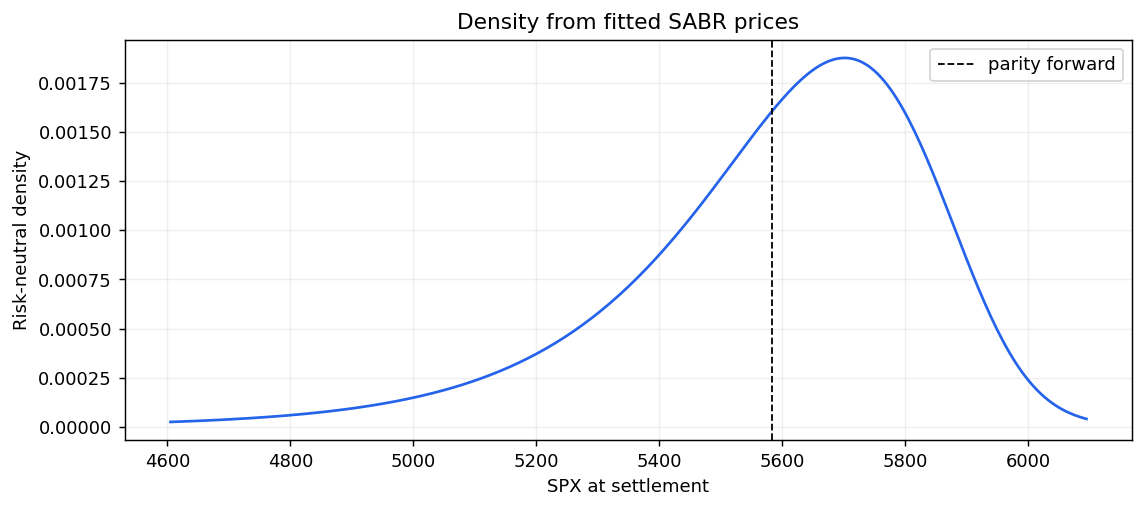

In [13]:
assets_path = DATA_DIR / snapshot.session / f"{snapshot.file_date}_assets.csv"
density = run_snapshot(
    fit.parameters,
    str(assets_path),
    snapshot.requested_time,
    snapshot.settlement_time.strftime("%Y%m%d"),
    r=snapshot.rate,
)
comparison = pd.DataFrame({
    "input": ["forward", "T (years)"],
    "calibration": [snapshot.forward, snapshot.maturity],
    "density": [density["forward"], density["T"]],
})
comparison["difference"] = comparison["density"] - comparison["calibration"]
display(comparison)
print("Density checks:", density["checks"])
assert np.allclose(comparison["difference"], 0, atol=1e-8)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(density["density_strikes"], density["density"], color="#2563eb")
ax.axvline(snapshot.forward, color="black", linestyle="--", linewidth=1, label="parity forward")
ax.set(xlabel="SPX at settlement", ylabel="Risk-neutral density", title="Density from fitted SABR prices")
ax.legend(); ax.grid(alpha=0.2)
plt.show()

## 9. Save and inspect the CSV outputs

This runs the same public entry point as the command-line script. The summary contains parameters and pricing inputs; the quote file contains every target and its model price and residual.

In [14]:
output_dir = PROJECT_ROOT / "calibration_output"
saved_summary = calibrate_times([TARGET_TIME], output_dir=output_dir, beta=0.7)
summary_columns = ["requested_time", "status", "settlement_time", "forward", "T", "r", "atm_strike", "alpha", "beta", "rho", "nu", "price_rmse", "within_bid_ask", "target_count"]
display(saved_summary[summary_columns])
quote_file = output_dir / saved_summary.loc[0, "quote_fit_file"]
print("Summary:", output_dir / "calibration_summary.csv")
print("Quote-level fit:", quote_file)
display(pd.read_csv(quote_file).head(8))

Summary: /Users/calvinliu/Desktop/Stochastic Proj/calibration_output/calibration_summary.csv
Quote-level fit: /Users/calvinliu/Desktop/Stochastic Proj/calibration_output/fit_RTH_2025-04-02_093124_000000_quotes.csv


,requested_time,status,settlement_time,forward,T,r,atm_strike,alpha,beta,rho,nu,price_rmse,within_bid_ask,target_count
0,2025-04-02 09:31:24,ok,2025-04-17 09:30:00,5582.713824,0.041093,0.04365,5575.0,2.929337,0.7,-0.824886,2.46152,0.914427,8,75


,kind,strike,bid,ask,mid,model_vol,model_price,price_error,within_bid_ask
0,put,4600.0,3.0,3.2,3.10,0.404019,1.254385,-1.845615,False
1,put,4625.0,3.1,3.4,3.25,0.399294,1.395519,-1.854481,False
2,put,4650.0,3.3,3.5,3.40,0.394575,1.553055,-1.846945,False
3,put,4675.0,3.4,3.7,3.55,0.389862,1.728961,-1.821039,False
4,put,4700.0,3.6,3.8,3.70,0.385154,1.925447,-1.774553,False
5,put,4725.0,3.8,4.0,3.90,0.380450,2.144997,-1.755003,False
6,put,4750.0,4.0,4.2,4.10,0.375751,2.390402,-1.709598,False
7,put,4775.0,4.2,4.4,4.30,0.371056,2.664799,-1.635201,False
